# 09 · Einstein radius and proper motion

The angular Einstein radius θ_E follows from the normalised source radius ρ of a finite-source fit and the angular
source radius θ⋆: θ_E = θ⋆ / ρ, and the relative proper motion μ = θ_E / t_E. θ⋆ comes from the de-reddened
colour and magnitude of the source, calibrated on the red giant clump (RGC):

1. (V−I, I) of the source and of the RGC centroid in the instrumental colour–magnitude diagram;
2. (V−I)₀ and I₀ of the source from its offset to the RGC, whose de-reddened values are known
   ((V−I)_RGC,0 = 1.06, Bensby et al. 2013; I_RGC,0 of the field, e.g. Nataf et al. 2013);
3. V−K from V−I (dwarf sequence of Pecaut & Mamajek 2013), and θ⋆ from the surface-brightness relation of
   Kervella et al. (2004).

We use the published values of KMT-2024-BLG-1209 (Han et al. 2025, Tables 3 and 4).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import lenscape
from lenscape import config, figures
from lenscape import source

In [2]:
# Han et al. (2025), Table 4 (instrumental CMD) and Table 3 (outer solution)
vi_s, i_s = 2.554, 20.833
vi_rgc, i_rgc, i_rgc0 = 2.627, 16.660, 14.533
rho, tE = 0.73e-3, 73.13

r = source.source_chain(vi_s, i_s, vi_rgc, i_rgc, i_rgc0, rho, tE)
print(f"(V-I)_0 = {r['vi0']:.3f}, I_0 = {r['i0']:.3f}  (paper 0.987, 18.705)")
print(f"theta_*  = {r['theta_star']:.3f} uas            (paper 0.783 +- 0.089; see below)")
print(f"theta_E  = {r['theta_E']:.3f} mas            (paper 1.133 +- 0.378)")
print(f"mu_rel   = {r['mu']:.2f} mas/yr")

(V-I)_0 = 0.987, I_0 = 18.706  (paper 0.987, 18.705)
theta_*  = 0.828 uas            (paper 0.783 +- 0.089; see below)
theta_E  = 1.134 mas            (paper 1.133 +- 0.378)
mu_rel   = 5.66 mas/yr


The de-reddened colour and magnitude agree with the paper. θ⋆ is 6 % larger: lenscape converts V−I to V−K with
the dwarf sequence of Pecaut & Mamajek (2013), the paper with Bessell & Brett (1988); the difference is well within
the quoted uncertainty. (θ_E agrees with the paper's value only by coincidence of the ρ used here.)

## Uncertainties

`sample_chain` propagates samples of (ρ, t_E) — for example from an MCMC chain (notebook 08) — together with the
errors of the source colour and magnitude and the scatter of the surface-brightness relation. Here we draw
(ρ, t_E) from the published values and errors.

theta_E = 1.12 -0.21 +0.29 mas


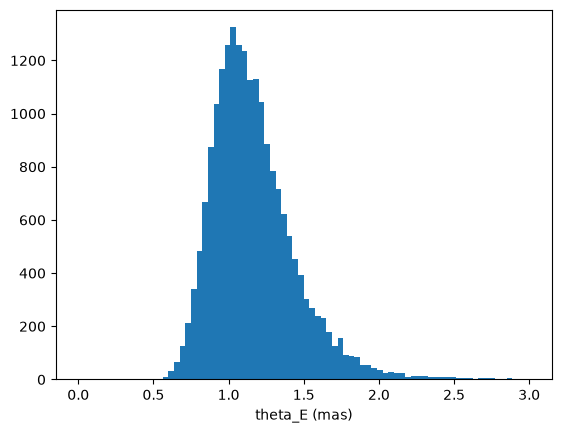

In [3]:
rng = np.random.default_rng(0)
rho_s = rng.normal(0.73e-3, 0.14e-3, 20000)
tE_s = rng.normal(73.13, 3.81, 20000)
rho_s = rho_s[rho_s > 0]; tE_s = tE_s[:len(rho_s)]
thE, mu = source.sample_chain(rho_s, tE_s, r["vi0"], r["i0"], sig_vi0=0.087, sig_i0=0.020, frac_theta=0.05)
lo, md_, hi = np.percentile(thE, [15.87, 50, 84.13])
print(f"theta_E = {md_:.2f} -{md_ - lo:.2f} +{hi - md_:.2f} mas")
plt.hist(thE, 80, range=(0, 3)); plt.xlabel("theta_E (mas)");